In [1]:
import anndata as ad
import os
spatial_dir = '/work/magroup/skrieger/Syndri/data/xenium_noise_experiment'


st_data = ad.read_h5ad(os.path.join(spatial_dir,"cosmx_nsclc_Lung12_adata_annotated_dropout_1pct.h5ad"))
st_data

AnnData object with n_obs × n_vars = 74025 × 958
    obs: 'fov', 'cell_ID', 'tissue', 'CenterX_local_px', 'CenterY_local_px', 'CenterX_global_px', 'CenterY_global_px', 'sdimx', 'sdimy', 'cell_ID_long', 'Area', 'AspectRatio', 'Width', 'Height', 'Mean.CD298', 'Max.CD298', 'Mean.G', 'Max.G', 'Mean.Y', 'Max.Y', 'Mean.R', 'Max.R', 'Mean.DAPI', 'Max.DAPI', 'dualfiles', 'Slide_name', 'Run_name', 'ISH.concentration', 'Dash', 'slide_ID_numeric', 'Run_Tissue_name', 'Panel', 'Diversity', 'totalcounts', 'log10totalcounts', 'background', 'remove_flagged_cells', 'patient', 'cell_type_orig', 'niche', 'prop_tumor_in_100_neighbors', 'cell_type', 'batch', 'split_X_first_type', 'split_X_n_cell_types', 'split_X_primary_cell_type', 'split_X_purification_status', 'split_X_w1_primary'
    uns: 'rctd_cell_type_names_X', 'rctd_postprocessing_X', 'rctd_run_metadata_X', 'simulated_dropout', 'source_h5_files_X', 'split_purification'
    obsm: 'X_pca_harmony_Lung12', 'rctd_weights_X', 'rctd_weights_doublet_X'
    

In [2]:
# import scanpy as sc
import numpy as np
# st_data = st_data[st_data.obs['source_h5']=='GSM9509174_breast_breast_B1_B1_3_cell_feature_matrix.h5']
idx = np.random.choice(st_data.n_obs, size=int(st_data.n_obs * 0.2), replace=False)
st_data = st_data[idx]


<Axes: ylabel='Count'>

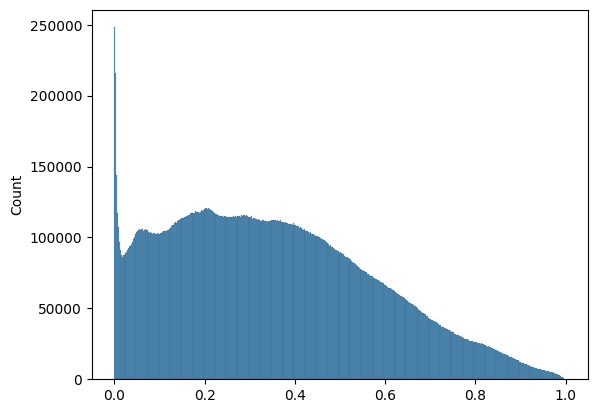

In [2]:
import seaborn as sns
vals = st_data.layers['admix_probs_X'].toarray().ravel()
vals = vals[vals>0]
sns.histplot(x=vals)

In [3]:
import sys
from argparse import Namespace

import anndata as ad

sys.path.insert(0, "/home/jwinchel/Syndri/eval")
from metrics_eval import (
    cleaned_counts_for_removed_fraction_maybe_grouped,
    sanitize_numeric_matrix,
)

args = Namespace(
    cleaning_mode="probability_scale",
    probability_transform="power",
    probability_power=2.0,
    probability_sigmoid_midpoint=0.5,
    probability_sigmoid_steepness=10.0,
    tcell_probability_removal_scale=1.0,
    cell_type_specific_removal=True,
)
st_data = st_data[st_data.obs['cell_type']!='nan']
X = sanitize_numeric_matrix(st_data.X.copy())
probs = st_data.layers["admix_probs_X"]
labels = st_data.obs["cell_type"]

X_cleaned, threshold, achieved, removal_scale, group_thresholds, group_scales, group_achieved = (
    cleaned_counts_for_removed_fraction_maybe_grouped(
        X,
        probs,
        target_removed_fraction=0.2,
        args=args,
        labels=labels,
    )
)

st_data.layers["syndri_cleaned_20pct"] = X_cleaned



/home/jwinchel/miniconda3/envs/rctd/lib/python3.10/site-packages/anndata/utils.py:429: FutureWarning: Importing read_csv from `anndata` is deprecated. Import anndata.io.read_csv instead.
  warnings.warn(msg, FutureWarning)
/home/jwinchel/miniconda3/envs/rctd/lib/python3.10/site-packages/anndata/utils.py:429: FutureWarning: Importing read_excel from `anndata` is deprecated. Import anndata.io.read_excel instead.
  warnings.warn(msg, FutureWarning)
/home/jwinchel/miniconda3/envs/rctd/lib/python3.10/site-packages/anndata/utils.py:429: FutureWarning: Importing read_hdf from `anndata` is deprecated. Import anndata.io.read_hdf instead.
  warnings.warn(msg, FutureWarning)
/home/jwinchel/miniconda3/envs/rctd/lib/python3.10/site-packages/anndata/utils.py:429: FutureWarning: Importing read_loom from `anndata` is deprecated. Import anndata.io.read_loom instead.
  warnings.warn(msg, FutureWarning)
/home/jwinchel/miniconda3/envs/rctd/lib/python3.10/site-packages/anndata/utils.py:429: FutureWarning: 

/home/jwinchel/miniconda3/envs/rctd/lib/python3.10/site-packages/scanpy/preprocessing/_normalization.py:233: UserWarning: Some cells have zero counts
  warn(UserWarning("Some cells have zero counts"))


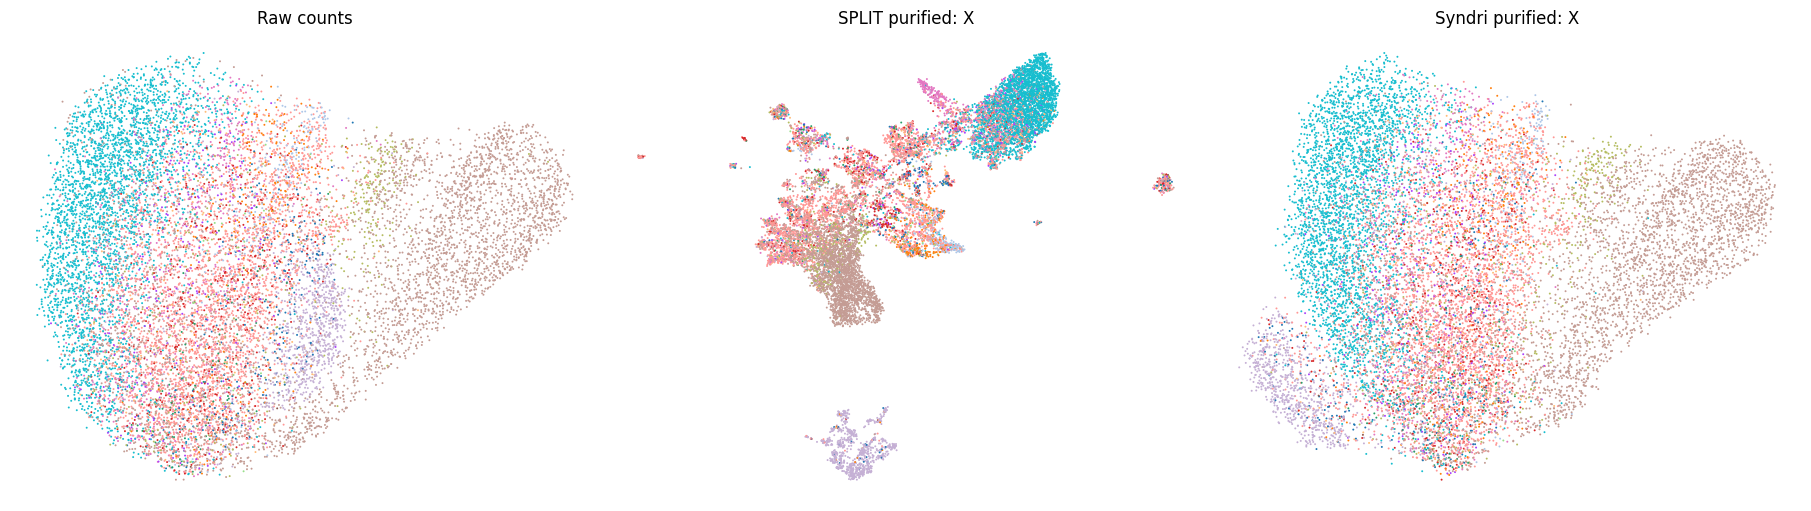

In [4]:
import numpy as np
import matplotlib.pyplot as plt
import scanpy as sc
import scipy.sparse as sp

# ------------------------------------------------------------------
# Configuration
# ------------------------------------------------------------------
layer_map = {
    "Raw counts": None,  # adata.X
    # "Transcript dropout: trial 0": "trial_0",
    "SPLIT purified: X": "split_purified_counts_X",
    "Syndri purified: X": "syndri_cleaned_20pct",
}

color_by = "cell_type"  # replace with your desired adata.obs column
n_top_genes = 1000
n_pcs = 50
n_neighbors = 15
random_state = 42


# ------------------------------------------------------------------
# Validation
# ------------------------------------------------------------------
missing_layers = [
    layer
    for layer in layer_map.values()
    if layer is not None and layer not in st_data.layers
]

if missing_layers:
    raise KeyError(f"Missing layers: {missing_layers}")

# if color_by not in st_data.obs:
#     raise KeyError(f"{color_by!r} is not present in adata.obs")


# ------------------------------------------------------------------
# Helper for extracting one raw-count matrix
# ------------------------------------------------------------------
def get_matrix(adata, layer):
    """Return an independent copy of .X or the specified layer."""
    X = adata.X if layer is None else adata.layers[layer]
    return X.copy()


# ------------------------------------------------------------------
# Select one common set of HVGs using the original raw counts
# ------------------------------------------------------------------
hvg_adata = st_data.copy()
hvg_adata.X = get_matrix(st_data, layer=None)

sc.pp.normalize_total(hvg_adata, target_sum=1e4)
sc.pp.log1p(hvg_adata)

# sc.pp.highly_variable_genes(
#     hvg_adata,
#     n_top_genes=n_top_genes,
#     flavor="seurat",
# )

# hvg_names = hvg_adata.var_names[hvg_adata.var["highly_variable"]].copy()

# print(f"Using {len(hvg_names):,} common highly variable genes")


# ------------------------------------------------------------------
# Compute a separate UMAP for each count matrix
# ------------------------------------------------------------------
umap_adatas = {}

for title, layer in layer_map.items():
    current = st_data.copy()
    current.X = get_matrix(st_data, layer)

    # Use exactly the same genes in all three analyses
    # current = current[:, hvg_names].copy()

    # Standard single-cell preprocessing
    sc.pp.normalize_total(current, target_sum=1e4)
    sc.pp.log1p(current)

    sc.pp.pca(
        current,
        n_comps=min(n_pcs, current.n_vars - 1),
        random_state=random_state,
    )

    sc.pp.neighbors(
        current,
        n_neighbors=n_neighbors,
        n_pcs=min(n_pcs, current.obsm["X_pca"].shape[1]),
        random_state=random_state,
    )

    sc.tl.umap(
        current,
        random_state=random_state,
    )

    umap_adatas[title] = current


# ------------------------------------------------------------------
# Plot the three UMAPs side by side
# ------------------------------------------------------------------
fig, axes = plt.subplots(
    1,
    len(umap_adatas),
    figsize=(6 * len(umap_adatas), 5),
    constrained_layout=True,
)

for ax, (title, current) in zip(axes, umap_adatas.items()):
    sc.pl.umap(
        current,
        color=color_by,
        title=title,
        ax=ax,
        show=False,
        frameon=False,
        legend_loc=None,
        size=8,
    )

# Add one shared legend using the final axis
handles, labels = axes[-1].get_legend_handles_labels()

if handles:
    fig.legend(
        handles,
        labels,
        title=color_by,
        loc="center left",
        bbox_to_anchor=(1.01, 0.5),
        frameon=False,
    )

plt.show()

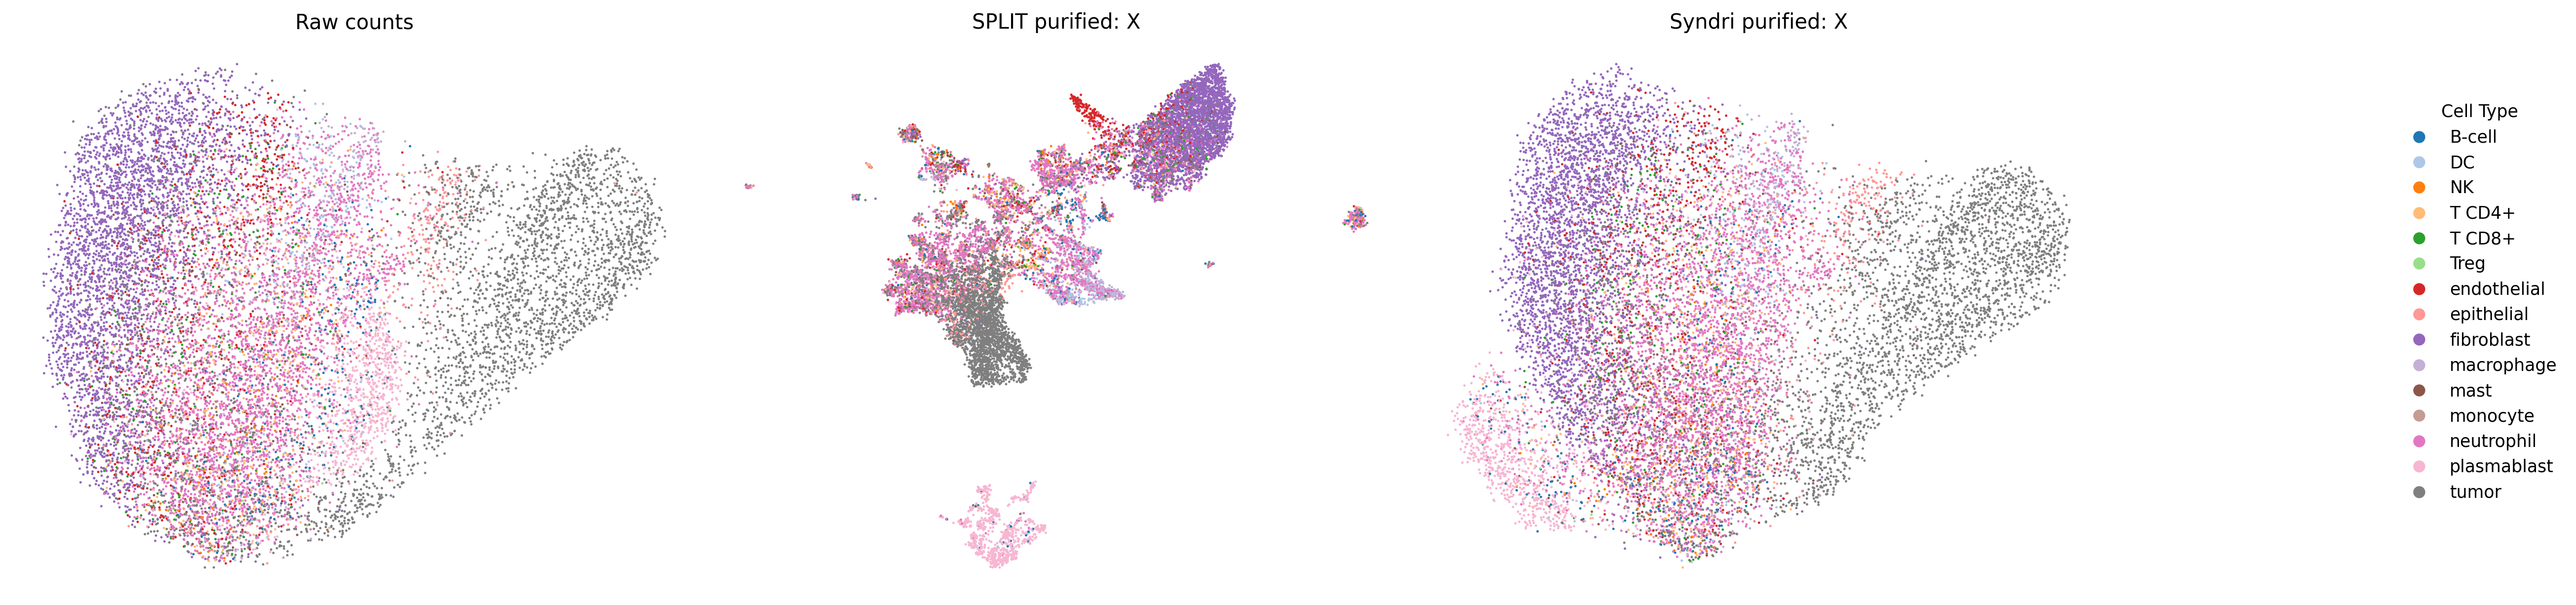

In [19]:
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.colors import to_hex
import seaborn as sns
import scanpy as sc

# ------------------------------------------------------------
# Configuration
# ------------------------------------------------------------
color_by = "cell_type"
palette_name = "tab20"   # e.g. "tab10", "tab20", "Set3", "husl"
legend_ncol = 1

items = list(umap_adatas.items())

# Collect categories across all datasets
categories = sorted({
    str(value)
    for _, current in items
    for value in current.obs[color_by].dropna().unique()
})

# Generate one consistent color per category
palette_colors = sns.color_palette(
    palette_name,
    n_colors=len(categories),
)

palette = {
    category: to_hex(color)
    for category, color in zip(categories, palette_colors)
}

# Ensure all AnnData objects use the same categorical ordering
# and the same Scanpy color metadata
for _, current in items:
    current.obs[color_by] = pd.Categorical(
        current.obs[color_by].astype(str),
        categories=categories,
        ordered=True,
    )

    current.uns[f"{color_by}_colors"] = [
        palette[category]
        for category in categories
    ]


# ------------------------------------------------------------
# Plot UMAPs
# ------------------------------------------------------------
fig, axes = plt.subplots(
    1,
    len(items),
    figsize=(6 * len(items) + 3, 5),
    squeeze=False,
    dpi=250,
)

axes = axes.ravel()

for ax, (title, current) in zip(axes, items):
    sc.pl.umap(
        current,
        color=color_by,
        palette=palette,
        title=title,
        ax=ax,
        show=False,
        frameon=False,
        legend_loc=None,
        size=8,
    )


# ------------------------------------------------------------
# Shared legend
# ------------------------------------------------------------
legend_handles = [
    Line2D(
        [0],
        [0],
        marker="o",
        linestyle="",
        markerfacecolor=palette[category],
        markeredgecolor="none",
        markersize=7,
        label=category,
    )
    for category in categories
]

fig.legend(
    handles=legend_handles,
    labels=categories,
    title=color_by.replace("_", " ").title(),
    loc="center right",
    bbox_to_anchor=(0.995, 0.5),
    frameon=False,
    ncol=legend_ncol,
)

# Reserve space on the right for the legend
fig.tight_layout(rect=[0, 0, 0.82, 1])

plt.show()

In [30]:
color_by

'harmony_cell_type'

In [ ]:
st_data.obsm["X_umap_raw"] = umap_adatas["Raw counts"].obsm["X_umap"].copy()
st_data.obsm["X_umap_trial_0"] = (
    umap_adatas["Transcript dropout: trial 0"].obsm["X_umap"].copy()
)
st_data.obsm["X_umap_split_trial_0"] = (
    umap_adatas["SPLIT purified: trial 0"].obsm["X_umap"].copy()
)

fig, axes = plt.subplots(
    1,
    len(umap_adatas),
    figsize=(6 * len(umap_adatas), 5),
    constrained_layout=True,
)

for ax, (title, current) in zip(axes, umap_adatas.items()):
    sc.pl.umap(
        current,
        color=color_by,
        title=title,
        ax=ax,
        show=False,
        frameon=False,
        legend_loc=None,
        size=8,
    )

# Add one shared legend using the final axis
handles, labels = axes[-1].get_legend_handles_labels()

if handles:
    fig.legend(
        handles,
        labels,
        title=color_by,
        loc="center left",
        bbox_to_anchor=(1.01, 0.5),
        frameon=False,
    )

plt.show()